# Classificador Distância Mínima ao Centroide — versão robusta a outliers

*Implementação com scikit-learn · base processada (sem duplicatas, z-score)*

O centroide de cada classe é substituído pela **mediana** de cada atributo, que não é afetada por valores extremos, e a distância euclidiana pela distância de **Manhattan** (L1). A mediana é justamente o ponto que minimiza a soma das distâncias L1 às amostras da classe:

$$\hat{y}(\mathbf{x}) = \arg\min_i \|\mathbf{x} - \tilde{\mathbf{m}}_i\|_1, \qquad \tilde{\mathbf{m}}_i = \text{mediana das amostras da classe } i$$

Protocolo (OBS 1–4 do enunciado): 100 rodadas treino-teste independentes e estratificadas para cada separação 20/80, 30/70, 50/50, 70/30 e 80/20.

## Dados

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # antes do numpy: evita falta de memória do OpenBLAS no Windows

import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
from avaliacao import (SPLITS, carregar, avaliar, estatisticas, matrizes_confusao, grafico_splits,
                       por_classe, grafico_por_classe, resumo, salvar)

pd.set_option("display.max_rows", 200)

X, y, classes = carregar(processada=True)
print(f"{len(y)} instâncias | {X.shape[1]} atributos | {len(classes)} classes: {list(classes)}")

5406 instâncias | 4 atributos | 4 classes: ['Move-Forward', 'Sharp-Right-Turn', 'Slight-Left-Turn', 'Slight-Right-Turn']


## Modelo

In [2]:
from sklearn.neighbors import NearestCentroid

MODELOS = {"DMC robusto": NearestCentroid(metric="manhattan")}  # centroide = mediana, distância de Manhattan

## Execução
100 rodadas × 5 separações. Em cada rodada, todos os modelos usam a mesma divisão treino/teste.

In [3]:
res, confusoes = avaliar(MODELOS, X, y, classes)
salvar(res, "classification_sklearn", "distancia_minima_centroide_robust")

## OBS 1 e 2 — Estatísticas de acurácia e tempos de treinamento/teste (ms)

In [4]:
estatisticas(res).round(4)

,,média,desvio,máxima,mínima,mediana,t_treino_ms,t_teste_ms
split,modelo,,,,,,,
20/80,DMC robusto,0.8146,0.0096,0.8351,0.7882,0.8154,2.4992,1.9957
30/70,DMC robusto,0.8168,0.0080,0.8325,0.7933,0.8180,1.9919,1.2147
50/50,DMC robusto,0.8193,0.0079,0.8343,0.7987,0.8193,2.2170,1.0739
70/30,DMC robusto,0.8189,0.0094,0.8397,0.7873,0.8187,2.4732,1.0773
80/20,DMC robusto,0.8205,0.0094,0.8457,0.7939,0.8202,2.7488,1.1738


## OBS 2 — Matrizes de confusão da melhor e da pior rodada

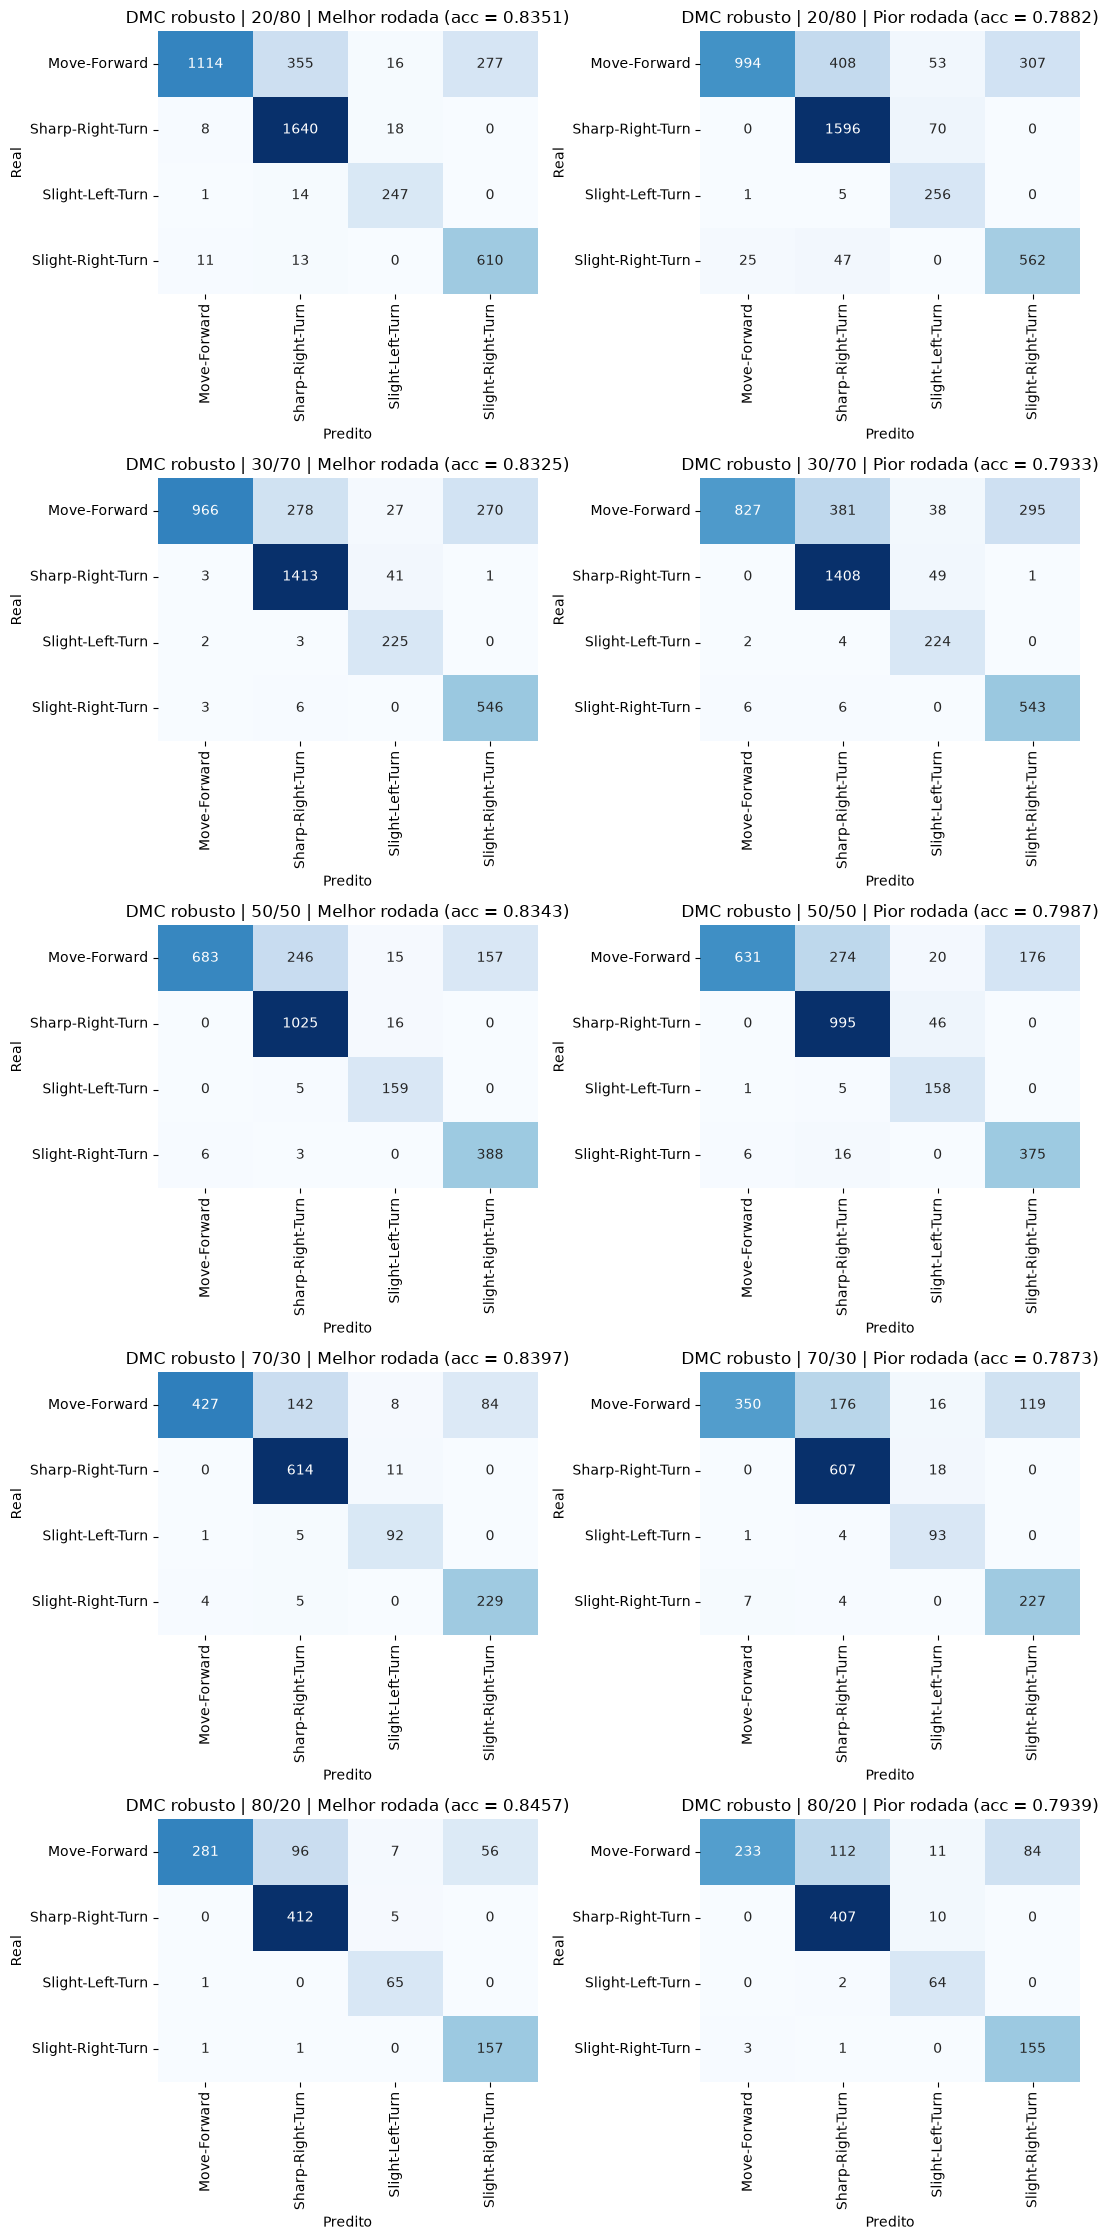

In [5]:
matrizes_confusao(res, confusoes, classes, splits=SPLITS)

## OBS 3 — Efeito da separação treino/teste

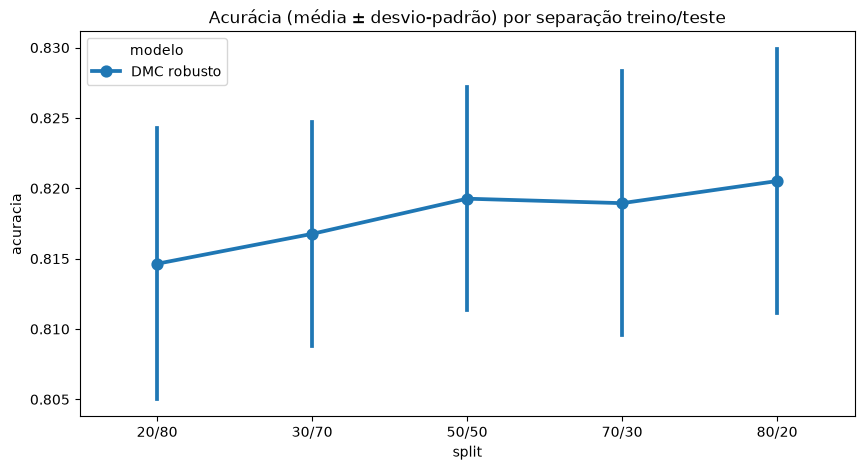

In [6]:
grafico_splits(res)

## OBS 4 — Desempenho por classe (taxa de acerto de cada classe)

In [7]:
por_classe(res, classes).round(4)

média  desvio  máxima  mínima  mediana
classe            split modelo                                              
Move-Forward      20/80 DMC robusto  0.5902  0.0165  0.6322  0.5409   0.5900
                  30/70 DMC robusto  0.5935  0.0145  0.6269  0.5367   0.5931
                  50/50 DMC robusto  0.5947  0.0148  0.6276  0.5568   0.5958
                  70/30 DMC robusto  0.5938  0.0202  0.6490  0.5295   0.5930
                  80/20 DMC robusto  0.5948  0.0210  0.6545  0.5295   0.5932
Sharp-Right-Turn  20/80 DMC robusto  0.9765  0.0128  0.9922  0.9406   0.9811
                  30/70 DMC robusto  0.9779  0.0098  0.9911  0.9438   0.9791
                  50/50 DMC robusto  0.9790  0.0098  0.9942  0.9558   0.9827
                  70/30 DMC robusto  0.9786  0.0088  0.9936  0.9584   0.9800
                  80/20 DMC robusto  0.9799  0.0086  0.9976  0.9592   0.9808
Slight-Left-Turn  20/80 DMC robusto  0.9529  0.0164  0.9771  0.8969   0.9580
                  30/70 DMC robusto  0.9551  0.0166  0.9826  0.9087   0.9609
                  50/50 DMC robusto  0.9552  0.0172  0.9939  0.9085   0.9573
                  70/30 DMC robusto  0.9570  0.0191  1.0000  0.8980   0.9592
                  80/20 DMC robusto  0.9559  0.0223  1.0000  0.8788   0.9545
Slight-Right-Turn 20/80 DMC robusto  0.9559  0.0276  0.9890  0.8738   0.9661
                  30/70 DMC robusto  0.9562  0.0255  0.9874  0.8739   0.9676
                  50/50 DMC robusto  0.9669  0.0120  0.9899  0.9270   0.9698
                  70/30 DMC robusto  0.9681  0.0133  0.9916  0.9202   0.9706
                  80/20 DMC robusto  0.9708  0.0151  1.0000  0.8931   0.9748

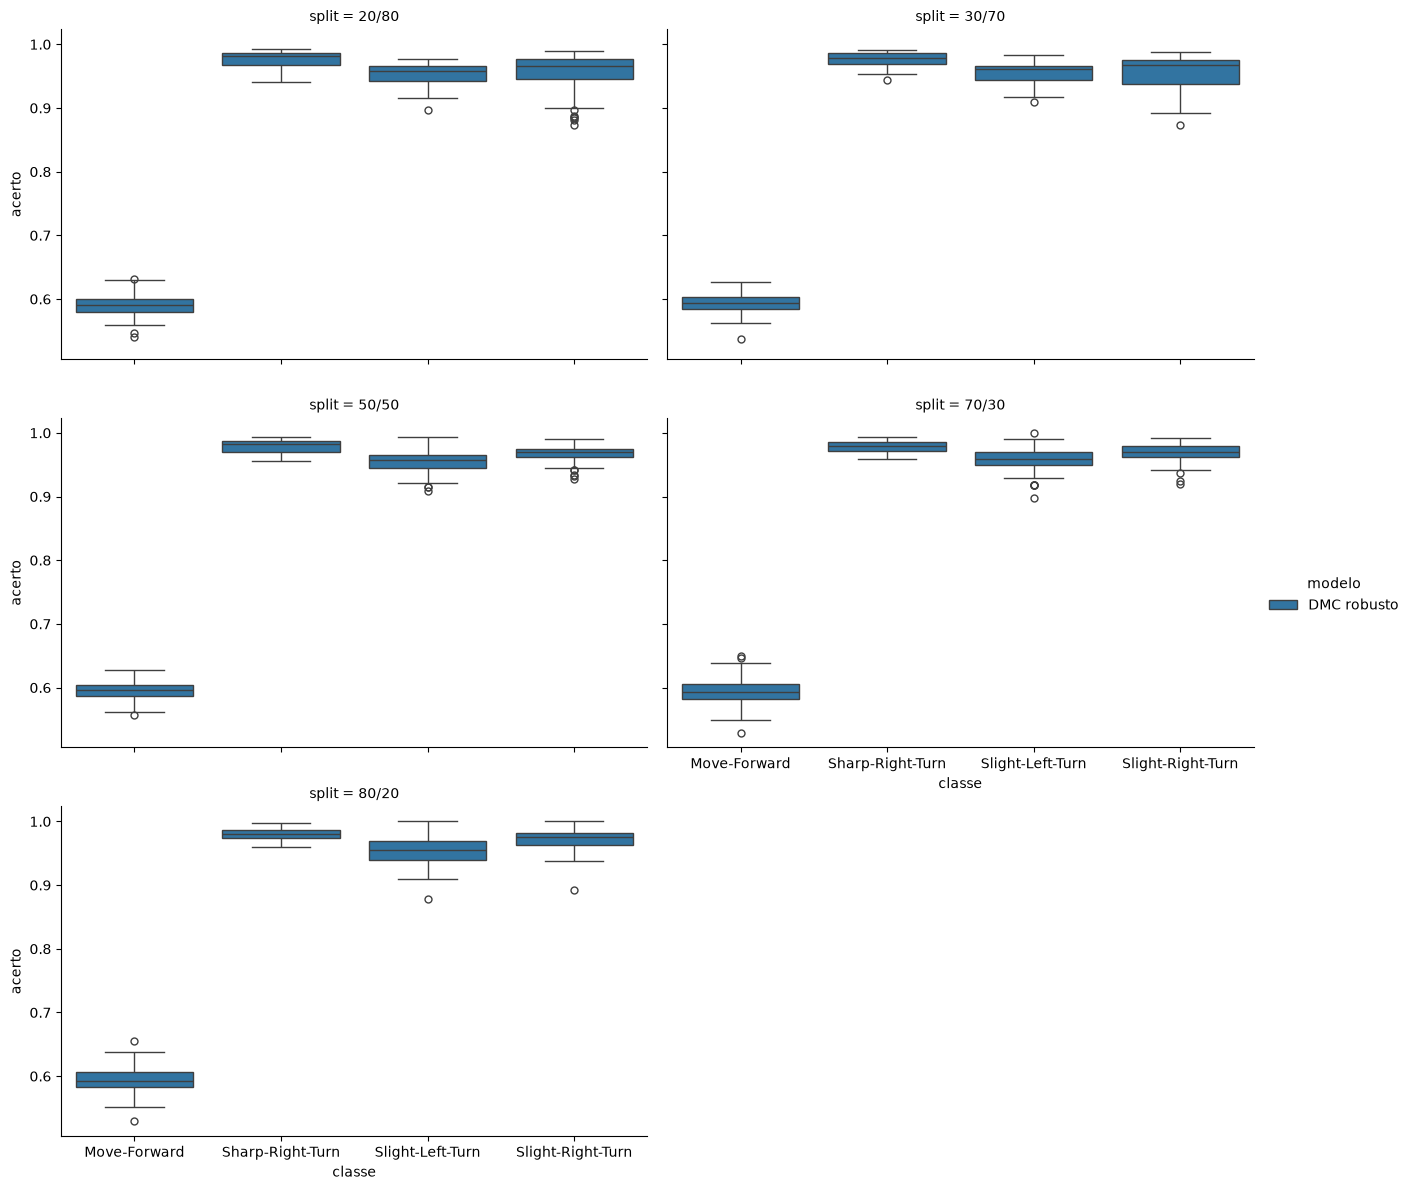

In [8]:
grafico_por_classe(res, classes)

## Resumo dos resultados

In [9]:
resumo(res, classes)

Melhor configuração: DMC robusto com split 80/20 -> acurácia média 0.8205

Tempo médio por rodada (ms):
  DMC robusto: treino 2.386 | teste 1.307

Efeito do split (acurácia média 20/80 -> 80/20):
  DMC robusto: 0.8146 -> 0.8205 (+0.0059)

Taxa de acerto média por classe (todas as rodadas):
  Move-Forward: 0.5934
  Slight-Left-Turn: 0.9553
  Slight-Right-Turn: 0.9636
  Sharp-Right-Turn: 0.9784
Classe mais fácil: Sharp-Right-Turn | mais difícil: Move-Forward
